In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [19]:
import numpy as np
import matplotlib.pyplot as plt

def Plot_Background_NoNorm(fig, ax, array2d,
                           xy_tick_labelsize=14,
                           cbar_tick_labelsize=12,
                           cbar_label_fontsize=16,
                           cbar_label_pad=20,
                           cbar_label_y=0.5,
                           cbar_label_rotation=0,
                           cbar_label_text="Value", # Colorbar 标签文本
                           data_vmin=None,          # 颜色映射的最小值 (None则自动)
                           data_vmax=None,cmap="Greys_r"):         # 颜色映射的最大值 (None则自动)
    """
    绘制背景图，不进行数据归一化，并调整坐标轴和Colorbar的样式。

    参数:
    - fig: matplotlib Figure 对象
    - ax: matplotlib Axes 对象
    - array2d: 二维数组数据 (原始值)
    - xy_tick_labelsize: XY轴刻度数字的字号
    - cbar_tick_labelsize: Colorbar刻度数字的字号
    - cbar_label_fontsize: Colorbar标签的字号
    - cbar_label_pad: Colorbar标签与Colorbar之间的距离 (points)
    - cbar_label_y: Colorbar标签的相对垂直位置 (0.0-1.0, 0.5表示中间)
    - cbar_label_rotation: Colorbar标签的旋转角度
    - cbar_label_text: Colorbar的标签文本
    - data_vmin: pcolormesh的vmin参数 (None则自动确定)
    - data_vmax: pcolormesh的vmax参数 (None则自动确定)
    """
    shape = array2d.shape[0]
    xgrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    ygrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    diff = np.diff(xgrid)[0] / 2.0
    xgrid += diff
    ygrid += diff
    xmesh, ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

    # 数据不再进行归一化

    bkg = ax.pcolormesh(
        xmesh, ymesh, array2d,  # 使用原始 array2d
        cmap=cmap,
        vmin=data_vmin,         # 使用新的 vmin 参数
        vmax=data_vmax,         # 使用新的 vmax 参数
        shading="auto"
    )
    ax.set_aspect("equal")

    # 1. 调整XY轴刻度标签大小
    ax.tick_params(axis='x', labelsize=xy_tick_labelsize)
    ax.tick_params(axis='y', labelsize=xy_tick_labelsize)

    # 添加Colorbar
    clb = fig.colorbar(bkg, ax=ax, fraction=0.046, pad=0.05)

    # 2. 调整Colorbar刻度标签大小
    clb.ax.tick_params(labelsize=cbar_tick_labelsize)

    # 3. 调整Colorbar标签的属性
    clb.set_label(cbar_label_text,  # 使用新的 cbar_label_text 参数
                  labelpad=cbar_label_pad,
                  y=cbar_label_y,
                  rotation=cbar_label_rotation,
                  size=cbar_label_fontsize)
    
    return bkg, clb




In [2]:
theta_mean = []
theta_std = []

for day in [95,96,100,101]:
    with np.load(f'../EHT-Imaging/{day}.npz') as data:
        theta_mean.append(data['arr_0']) # rad
        theta_std.append(data['arr_1']) # rad

In [ ]:
rg_per_pixel=0.51073125
condition2to9=np.array([[2<=np.sqrt((i-31.5)**2+(j-31.5)**2)*rg_per_pixel<=9 for j in range(64)] for i in range(64)])
condition2to9=np.array(condition2to9,dtype=np.float16)
condition2to9[condition2to9==False]=np.nan

In [20]:
std9596=np.sqrt(theta_std[1]*theta_std[1]+theta_std[0]*theta_std[0])/np.pi*180*condition2to9

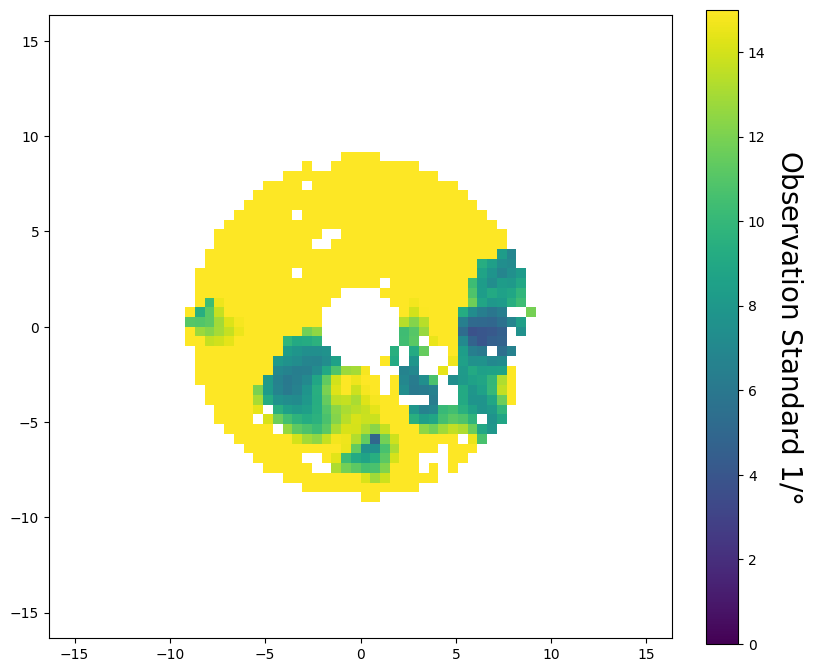

In [23]:

# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
Plot_Background_NoNorm(fig, ax, std9596,
                        xy_tick_labelsize=10,
                        cbar_tick_labelsize=10,
                        cbar_label_fontsize=20,
                        cbar_label_pad=27,
                        cbar_label_y=0.5,
                        cbar_label_rotation=270,
                        cbar_label_text=r"Observation Standard 1/$\degree$", # 自定义Colorbar标签
                        # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                        # 或者您可以手动指定，例如:
                        data_vmin=0,
                        data_vmax=15,
                        cmap="viridis"
                        )

# 添加主图的标题和轴标签（可选）
# ax.set_title("64x64 Data Visualization (No Normalization)", fontsize=16)

# 4. 自动调整布局
fig.tight_layout()
plt.savefig("fig?_9596.png")
# 5. 显示图像
plt.show()

In [24]:
std100101=np.sqrt(theta_std[3]*theta_std[3]+theta_std[2]*theta_std[2])/np.pi*180*condition2to9

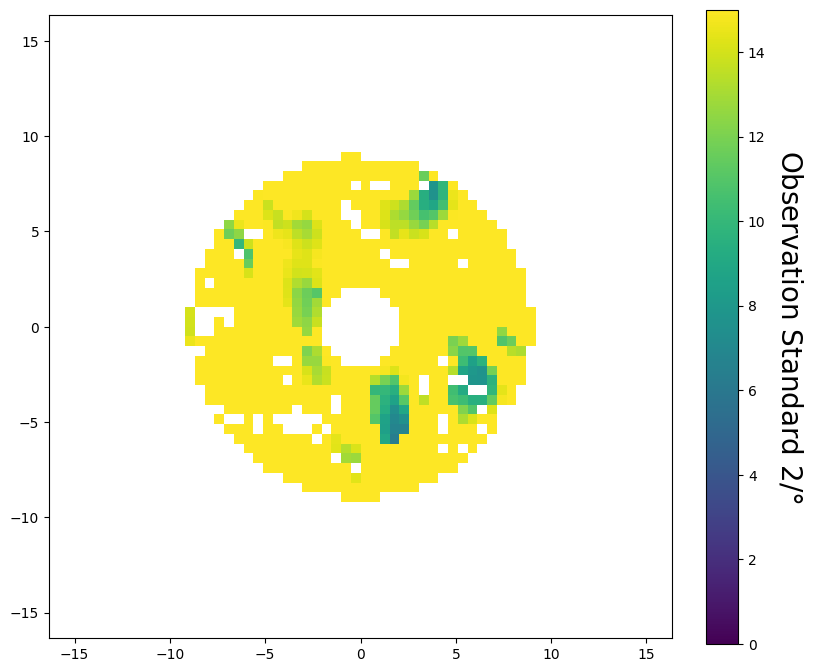

In [25]:

# 2. 创建 Figure 和 Axes 对象
fig, ax = plt.subplots(figsize=(8, 7))

# 3. 调用新的绘图函数 (不进行归一化)
Plot_Background_NoNorm(fig, ax, std100101,
                        xy_tick_labelsize=10,
                        cbar_tick_labelsize=10,
                        cbar_label_fontsize=20,
                        cbar_label_pad=27,
                        cbar_label_y=0.5,
                        cbar_label_rotation=270,
                        cbar_label_text=r"Observation Standard 2/$\degree$", # 自定义Colorbar标签
                        # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
                        # 或者您可以手动指定，例如:
                        data_vmin=0,
                        data_vmax=15,
                        cmap="viridis"
                        )

# 添加主图的标题和轴标签（可选）
# ax.set_title("64x64 Data Visualization (No Normalization)", fontsize=16)

# 4. 自动调整布局
fig.tight_layout()
plt.savefig("fig?_100101.png")
# 5. 显示图像
plt.show()